# **03 |** MapBiomas Perú: coberturas y transiciones

> **Objetivo:** caracterizar las coberturas de la provincia de Cusco y cuantificar los cambios entre bosque natural y áreas agropecuarias durante 2013–2025.
> 
> **Fuente:** MapBiomas Perú, Colección 4, resolución de 30 m.
> 
> **Productos:** superficies por clase y año, matrices completas de transición, indicadores de pérdida y ganancia de bosque y un raster opcional de conversión de bosque a coberturas agropecuarias.

MapBiomas se utiliza como referencia temática. Los cambios de clase no demuestran por sí solos la causa del cambio ni sustituyen una validación independiente.

## 1. Configuración

Se reutiliza el Asset provincial creado en el notebook 01. Las clases de bosque natural y las coberturas agropecuarias se mantienen diferenciadas. La clase 15 (Pasto beta) se reporta por separado por su definición.

In [2]:
from pathlib import Path
import time
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd() / ".."

GEE_PROJECT = "cusco-land-cover"
AOI_ASSET = f"projects/{GEE_PROJECT}/assets/cusco_01_aoi"
MB_ASSET = (
    "projects/mapbiomas-public/assets/peru/collection4/"
    "mapbiomas_peru_collection4_coverage_v1"
)

ANIO_INI = 2013
ANIO_FIN = 2025
ANIOS = list(range(ANIO_INI, ANIO_FIN + 1))

CLASES_BOSQUE_NATURAL = {3, 4, 5, 6}
CLASES_AGROPECUARIAS = {21, 35, 40}
CLASE_PASTO_BETA = 15
CLASE_PLANTACION_FORESTAL = 9

ESCALA = 30
MAX_PIXELS = 1e13
TILE_SCALE = 4

PROJECT_ROOT = Path.cwd().parent
SALIDA = PROJECT_ROOT / "outputs" / "02_mapbiomas_cover_ref"
SALIDA.mkdir(parents=True, exist_ok=True)

EXPORTAR_RASTER_CAMBIO = False
ASSET_CAMBIO = f"projects/{GEE_PROJECT}/assets/cusco_02_bosque_a_agropecuario"

In [3]:

# ============================================================
# LEYENDA MAPBIOMAS PERÚ - COLECCIÓN 4
# ============================================================

# Diccionario de códigos de píxel y sus nombres.
NOMBRES = {
    # Nivel 1: categorías generales
    1: "Formación boscosa",
    10: "Formación natural no boscosa",
    14: "Área agropecuaria",
    22: "Área sin vegetación",
    26: "Cuerpo de agua",
    27: "No observado",

    # Nivel 3: clases específicas
    3: "Bosque",
    4: "Bosque seco",
    5: "Manglar",
    6: "Bosque inundable",

    11: "Formación herbácea inundable",
    51: "Herbazal inundable de tierras bajas",
    82: "Herbazal inundable altoandino",
    12: "Formación herbácea",
    13: "Formaciones arbustivas y otras",
    66: "Matorral y otros arbustales",
    70: "Loma costera (beta)",

    21: "Mosaico agropecuario",
    9: "Plantación forestal",
    35: "Palma aceitera",
    40: "Arroz (beta)",
    15: "Pasto (beta)",

    24: "Infraestructura urbana",
    30: "Minería",
    23: "Playa",
    92: "Superficie rocosa",
    52: "Superficie salina costera",
    61: "Superficie de salar",
    68: "Otra área natural sin vegetación",
    25: "Otra área antrópica sin vegetación",

    33: "Río, lago u océano",
    31: "Acuicultura",
    34: "Glaciar"
}


# ============================================================
# JERARQUÍA DE LA LEYENDA - COLECCIÓN 4
# ============================================================

# Nivel 1: categorías generales.
CLASES_NIVEL_1 = {
    1, 10, 14, 22, 26
}

# Nivel 2: categorías intermedias.
CLASES_NIVEL_2 = {
    11, 13
}

# Nivel 3: clases específicas de cobertura.
CLASES_NIVEL_3 = {
    3, 4, 5, 6,
    51, 82, 12, 66, 70,
    21, 9, 35, 40, 15,
    24, 30, 23, 92, 52, 61, 68, 25,
    33, 31, 34
}

# Clases que se excluyen del análisis de cobertura.
CLASE_SIN_INFORMACION = 27

# Códigos utilizados como unidad principal del análisis.
CLASES_ANALISIS = CLASES_NIVEL_3


In [4]:
def iniciar_gee():
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)

def evaluar_serie(objetos, etiquetas=None, pausa=0.3):
    etiquetas = etiquetas or [str(i) for i in range(len(objetos))]
    resultados = []
    for i, (objeto, etiqueta) in enumerate(zip(objetos, etiquetas), start=1):
        print(f"[{i}/{len(objetos)}] {etiqueta}...", end=" ")
        resultados.append(objeto.getInfo())
        print("OK")
        if pausa and i < len(objetos):
            time.sleep(pausa)
    return resultados

iniciar_gee()
aoi_fc = ee.FeatureCollection(AOI_ASSET)
aoi = aoi_fc.geometry()
mb = ee.Image(MB_ASSET)
area_km2 = ee.Number(aoi_fc.first().get("area_km2")).getInfo()

print(f"Provincia de Cusco: {area_km2:,.2f} km²")
print(f"Periodo: {ANIO_INI}–{ANIO_FIN}")
print("AOI:", AOI_ASSET)
print("MapBiomas:", MB_ASSET)

Provincia de Cusco: 529.18 km²
Periodo: 2013–2025
AOI: projects/cusco-land-cover/assets/cusco_01_aoi
MapBiomas: projects/mapbiomas-public/assets/peru/collection4/mapbiomas_peru_collection4_coverage_v1


## 2. Verificación de los datos

Se comprueba la disponibilidad de las bandas anuales y se identifican las clases presentes en la provincia.

In [5]:

# ============================================================
# DISPONIBILIDAD DE CLASES POR AÑO Y NIVEL
# ============================================================

# Verificar bandas disponibles
bandas = mb.bandNames().getInfo()

anios_disponibles = {
    int(b.split("_")[-1])
    for b in bandas
    if b.startswith("classification_")
}

faltantes = [a for a in ANIOS if a not in anios_disponibles]

if faltantes:
    raise ValueError(f"Faltan bandas de MapBiomas: {faltantes}")

# Información de proyección
proyeccion = mb.select(f"classification_{ANIO_INI}").projection()

print(f"Años disponibles: {min(anios_disponibles)}–{max(anios_disponibles)}")
print(f"CRS: {proyeccion.crs().getInfo()}")
print(f"Resolución: {proyeccion.nominalScale().getInfo()} m")


# ------------------------------------------------------------
# Histograma de códigos por año
# ------------------------------------------------------------

def histograma_clases(anio):
    imagen = mb.select(f"classification_{anio}")

    resultado = imagen.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=aoi,
        scale=ESCALA,
        crs=proyeccion,
        maxPixels=MAX_PIXELS,
        tileScale=TILE_SCALE
    )

    return resultado.get(f"classification_{anio}")


histogramas = evaluar_serie(
    [histograma_clases(a) for a in ANIOS],
    [f"Clases presentes {a}" for a in ANIOS]
)

# Diccionario: año -> código -> cantidad de píxeles
HISTOGRAMAS = {
    anio: {
        int(codigo): int(cantidad)
        for codigo, cantidad in (hist or {}).items()
    }
    for anio, hist in zip(ANIOS, histogramas)
}


# ------------------------------------------------------------
# Mostrar clases presentes por año y nivel
# ------------------------------------------------------------

NIVELES = {
    "Nivel 1 - Categorías generales": CLASES_NIVEL_1,
    "Nivel 2 - Categorías intermedias": CLASES_NIVEL_2,
    "Nivel 3 - Clases específicas": CLASES_NIVEL_3,
    "Sin información": {CLASE_SIN_INFORMACION}
}

for anio in ANIOS:
    presentes = set(HISTOGRAMAS[anio])

    print(f"\n{'=' * 75}")
    print(f"MAPBIOMAS - {anio}")
    print(f"{'=' * 75}")

    for nivel, codigos_nivel in NIVELES.items():
        codigos = sorted(presentes.intersection(codigos_nivel))

        print(f"\n{nivel}: {len(codigos)} códigos presentes")

        if not codigos:
            print("  Sin registros")
            continue

        for codigo in codigos:
            nombre = NOMBRES[codigo]
            cantidad = HISTOGRAMAS[anio][codigo]

            print(
                f"  {codigo:>3} | {nombre:<45} "
                f"| {cantidad:>12,} píxeles"
            )


# ------------------------------------------------------------
# Resumen de cantidad de clases por nivel y año
# ------------------------------------------------------------

resumen = []

for anio in ANIOS:
    presentes = set(HISTOGRAMAS[anio])

    fila = {"Año": anio}

    for nivel, codigos_nivel in NIVELES.items():
        fila[nivel] = len(presentes.intersection(codigos_nivel))

    resumen.append(fila)

df_niveles = pd.DataFrame(resumen).set_index("Año")

print("\nRESUMEN DE CÓDIGOS PRESENTES POR NIVEL")
display(df_niveles)


# ------------------------------------------------------------
# Códigos observados en todo el periodo
# ------------------------------------------------------------

CODIGOS_PRESENTES = sorted({
    codigo
    for hist in HISTOGRAMAS.values()
    for codigo in hist
})

print("\nCLASES PRESENTES EN TODO EL PERIODO")

for nivel, codigos_nivel in NIVELES.items():
    codigos = sorted(set(CODIGOS_PRESENTES).intersection(codigos_nivel))

    print(f"\n{nivel}: {len(codigos)} códigos")

    for codigo in codigos:
        anios_presencia = [
            anio for anio in ANIOS
            if codigo in HISTOGRAMAS[anio]
        ]

        print(
            f"  {codigo:>3} · {NOMBRES[codigo]}"
            f" | {len(anios_presencia)}/{len(ANIOS)} años"
        )


Años disponibles: 1985–2025
CRS: EPSG:4326
Resolución: 30.000000000000004 m
[1/13] Clases presentes 2013... OK
[2/13] Clases presentes 2014... OK
[3/13] Clases presentes 2015... OK
[4/13] Clases presentes 2016... OK
[5/13] Clases presentes 2017... OK
[6/13] Clases presentes 2018... OK
[7/13] Clases presentes 2019... OK
[8/13] Clases presentes 2020... OK
[9/13] Clases presentes 2021... OK
[10/13] Clases presentes 2022... OK
[11/13] Clases presentes 2023... OK
[12/13] Clases presentes 2024... OK
[13/13] Clases presentes 2025... OK

MAPBIOMAS - 2013

Nivel 1 - Categorías generales: 0 códigos presentes
  Sin registros

Nivel 2 - Categorías intermedias: 0 códigos presentes
  Sin registros

Nivel 3 - Clases específicas: 11 códigos presentes
    3 | Bosque                                        |        2,306 píxeles
    9 | Plantación forestal                           |       11,414 píxeles
   12 | Formación herbácea                            |      297,037 píxeles
   15 | Pasto (beta)    

,Nivel 1 - Categorías generales,Nivel 2 - Categorías intermedias,Nivel 3 - Clases específicas,Sin información
Año,,,,
2013,0,0,11,0
2014,0,0,11,0
2015,0,0,11,0
2016,0,0,11,0
2017,0,0,11,0
2018,0,0,11,0
2019,0,0,11,0
2020,0,0,12,0
2021,0,0,12,0



CLASES PRESENTES EN TODO EL PERIODO

Nivel 1 - Categorías generales: 0 códigos

Nivel 2 - Categorías intermedias: 0 códigos

Nivel 3 - Clases específicas: 12 códigos
    3 · Bosque | 13/13 años
    9 · Plantación forestal | 13/13 años
   12 · Formación herbácea | 13/13 años
   15 · Pasto (beta) | 13/13 años
   21 · Mosaico agropecuario | 13/13 años
   24 · Infraestructura urbana | 13/13 años
   30 · Minería | 6/13 años
   33 · Río, lago u océano | 13/13 años
   66 · Matorral y otros arbustales | 13/13 años
   68 · Otra área natural sin vegetación | 13/13 años
   82 · Herbazal inundable altoandino | 13/13 años
   92 · Superficie rocosa | 13/13 años

Sin información: 0 códigos


Se identificaron **12 clases específicas** de cobertura durante el periodo 2013–2025.
- Nivel 1 y nivel 2: 0 códigos. *MapBiomas registra los píxeles con los códigos de las clases específicas, no con los códigos de sus categorías agrupadoras.*
- ****Nivel 3: 12 códigos.**** Son las clases específicas detectadas en el ``aio``.

In [6]:

# ============================================================
# ANÁLISIS DE PRESENCIA: MINERÍA (CLASE 30)
# ============================================================

CODIGO = 30
NOMBRE = NOMBRES[CODIGO]

resultados_mineria = []

for anio in ANIOS:
    cantidad = HISTOGRAMAS[anio].get(CODIGO, 0)

    resultados_mineria.append({
        "Año": anio,
        "Píxeles": cantidad,
        "Superficie (ha)": cantidad * ESCALA**2 / 10000
    })

df_mineria = pd.DataFrame(resultados_mineria)

df_mineria["Presencia"] = df_mineria["Píxeles"].apply(
    lambda x: "Presente" if x > 0 else "No detectada"
)

print(f"Clase {CODIGO}: {NOMBRE}")
print(
    f"Años con presencia: "
    f"{(df_mineria['Píxeles'] > 0).sum()}/{len(ANIOS)}"
)

display(df_mineria)


# ============================================================
# AÑOS EN LOS QUE NO SE DETECTÓ MINERÍA
# ============================================================

anios_sin_mineria = df_mineria.loc[
    df_mineria["Píxeles"] == 0, "Año"
].tolist()

anios_con_mineria = df_mineria.loc[
    df_mineria["Píxeles"] > 0, "Año"
].tolist()

print("\nAños con minería detectada:", anios_con_mineria)
print("Años sin minería detectada:", anios_sin_mineria)


Clase 30: Minería
Años con presencia: 6/13


,Año,Píxeles,Superficie (ha),Presencia
0,2013,0,0.00,No detectada
1,2014,0,0.00,No detectada
2,2015,0,0.00,No detectada
3,2016,0,0.00,No detectada
4,2017,0,0.00,No detectada
5,2018,0,0.00,No detectada
6,2019,0,0.00,No detectada
7,2020,73,6.57,Presente
8,2021,124,11.16,Presente
9,2022,159,14.31,Presente



Años con minería detectada: [2020, 2021, 2022, 2023, 2024, 2025]
Años sin minería detectada: [2013, 2014, 2015, 2016, 2017, 2018, 2019]


La clase 30 (Minería) no registra píxeles entre 2013 y 2019. Su presencia comienza en 2020 con 73 píxeles (6.57 ha) y aumenta progresivamente hasta alcanzar 264 píxeles (23.76 ha) en 2024, manteniéndose en el mismo nivel en 2025.

Esto evidencia un incremento de la superficie clasificada como minería desde 2020. Sin embargo, no confirma por sí solo el inicio de actividades mineras, pues también puede estar influido por cambios en la clasificación satelital.

## 3. Superficie y ocupación por clase

Se calcula la superficie de cada clase para cada año. La ocupación porcentual se expresa respecto al área total del AOI; también se conserva la participación respecto al área clasificada.

In [7]:
# ============================================================
# SUPERFICIE ANUAL POR CLASE - MAPBIOMAS COLECCIÓN 4
# ============================================================

# Solo se consideran las clases específicas del nivel 3 con informarción.
CODIGOS_ANALISIS = sorted({
    3, 9, 12, 15, 21, 24,
    30, 33, 66, 68, 82, 92
})


def areas_por_clase(anio):
    clase = mb.select(f"classification_{anio}").rename("clase")

    # Máscara para conservar únicamente las clases del análisis.
    mascara = clase.remap(
        CODIGOS_ANALISIS,
        [1] * len(CODIGOS_ANALISIS),
        0
    ).eq(1)

    # Superficie en km² y código de clase.
    imagen = (
        ee.Image.pixelArea()
        .divide(1e6)
        .rename("km2")
        .addBands(clase)
        .updateMask(mascara)
    )

    resultado = imagen.reduceRegion(
        reducer=ee.Reducer.sum().group(
            groupField=1,
            groupName="clase"
        ),
        geometry=aoi,
        scale=ESCALA,
        crs=proyeccion,
        maxPixels=MAX_PIXELS,
        tileScale=TILE_SCALE
    )

    return resultado.get("groups")


# ------------------------------------------------------------
# Cálculo de superficies para todos los años
# ------------------------------------------------------------

grupos_anuales = evaluar_serie(
    [areas_por_clase(anio) for anio in ANIOS],
    [f"Superficie por clase {anio}" for anio in ANIOS]
)


# ------------------------------------------------------------
# Organización de resultados
# ------------------------------------------------------------

# Diccionario: año -> clase -> superficie en km².
SUPERFICIES = {}

for anio, grupos in zip(ANIOS, grupos_anuales):
    SUPERFICIES[anio] = {
        int(g["clase"]): float(g["sum"])
        for g in (grupos or [])
    }


# Se generan todas las combinaciones año-clase.
# Las clases sin presencia reciben superficie igual a cero.

filas = []

for anio in ANIOS:
    for codigo in CODIGOS_ANALISIS:
        km2 = SUPERFICIES[anio].get(codigo, 0.0)

        filas.append({
            "anio": anio,
            "clase": codigo,
            "nombre": NOMBRES[codigo],
            "km2": km2
        })

areas = pd.DataFrame(filas)


# ------------------------------------------------------------
# Indicadores de superficie y ocupación
# ------------------------------------------------------------

# Superficie total correspondiente a las clases analizadas.
areas["area_clasificada_km2"] = (
    areas.groupby("anio")["km2"].transform("sum")
)

areas["ha"] = areas["km2"] * 100

# Porcentaje respecto a la superficie total del AOI.
areas["ocupacion_aoi_pct"] = (
    areas["km2"] / area_km2 * 100
)

# Porcentaje respecto a la superficie clasificada del año.
areas["participacion_clasificada_pct"] = np.where(
    areas["area_clasificada_km2"] > 0,
    areas["km2"] / areas["area_clasificada_km2"] * 100,
    0
)


# ------------------------------------------------------------
# Ordenamiento y exportación
# ------------------------------------------------------------

areas = areas.sort_values(
    ["anio", "km2"],
    ascending=[True, False]
).reset_index(drop=True)

archivo_areas = SALIDA / "areas_por_clase.csv"
areas.to_csv(archivo_areas, index=False, encoding="utf-8-sig")


# ------------------------------------------------------------
# Resultados de los años inicial y final
# ------------------------------------------------------------

display(
    areas[
        areas["anio"].isin([ANIO_INI, ANIO_FIN])
    ].round(3)
)

print(f"\nClases analizadas: {len(CODIGOS_ANALISIS)}")
print(f"Años procesados: {len(ANIOS)}")
print(f"Registros generados: {len(areas)}")
print(f"Archivo guardado: {archivo_areas}")

[1/13] Superficie por clase 2013... OK
[2/13] Superficie por clase 2014... OK
[3/13] Superficie por clase 2015... OK
[4/13] Superficie por clase 2016... OK
[5/13] Superficie por clase 2017... OK
[6/13] Superficie por clase 2018... OK
[7/13] Superficie por clase 2019... OK
[8/13] Superficie por clase 2020... OK
[9/13] Superficie por clase 2021... OK
[10/13] Superficie por clase 2022... OK
[11/13] Superficie por clase 2023... OK
[12/13] Superficie por clase 2024... OK
[13/13] Superficie por clase 2025... OK


,anio,clase,nombre,km2,area_clasificada_km2,ha,ocupacion_aoi_pct,participacion_clasificada_pct
0,2013,12,Formación herbácea,258.334,529.178,25833.444,48.818,48.818
1,2013,21,Mosaico agropecuario,148.427,529.178,14842.665,28.048,28.049
2,2013,66,Matorral y otros arbustales,72.963,529.178,7296.328,13.788,13.788
3,2013,24,Infraestructura urbana,28.247,529.178,2824.686,5.338,5.338
4,2013,9,Plantación forestal,9.929,529.178,992.878,1.876,1.876
5,2013,68,Otra área natural sin vegetación,3.530,529.178,352.993,0.667,0.667
6,2013,82,Herbazal inundable altoandino,3.340,529.178,334.016,0.631,0.631
7,2013,3,Bosque,2.006,529.178,200.593,0.379,0.379
8,2013,15,Pasto (beta),1.664,529.178,166.414,0.314,0.314
9,2013,33,"Río, lago u océano",0.700,529.178,69.961,0.132,0.132



Clases analizadas: 12
Años procesados: 13
Registros generados: 156
Archivo guardado: d:\workspace\projects\project-collab\cusco-land-cover-analysis\outputs\02_mapbiomas_cover_ref\areas_por_clase.csv


## 4. Evolución de las coberturas

Se visualiza la trayectoria de las clases con mayor superficie en el año inicial. La tabla inferior compara la superficie de cada clase entre 2013 y 2025.

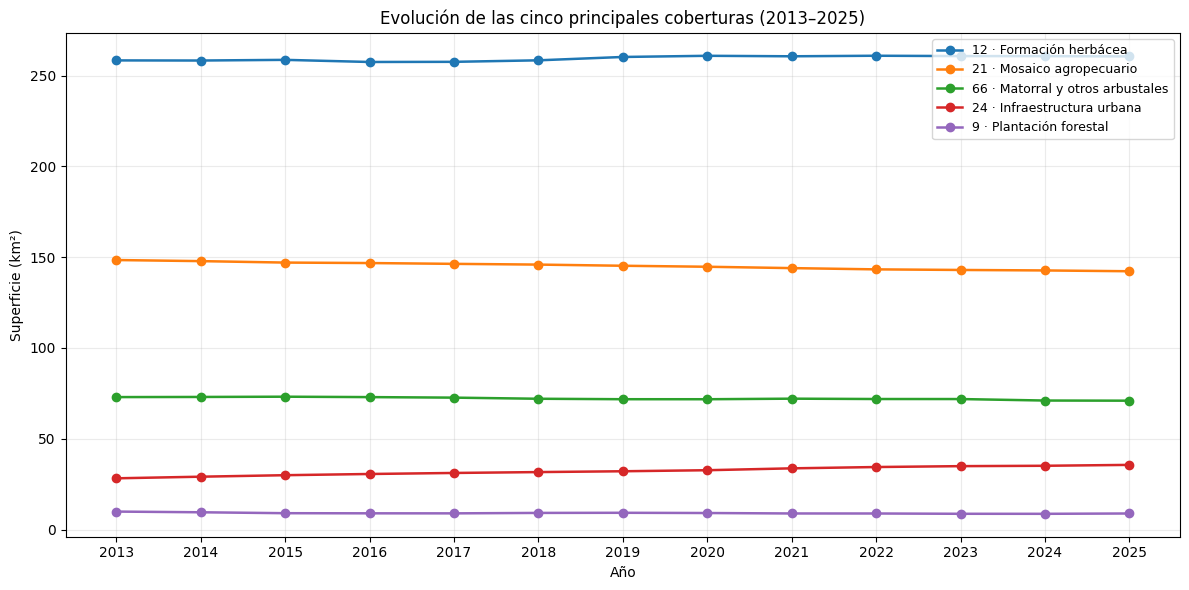

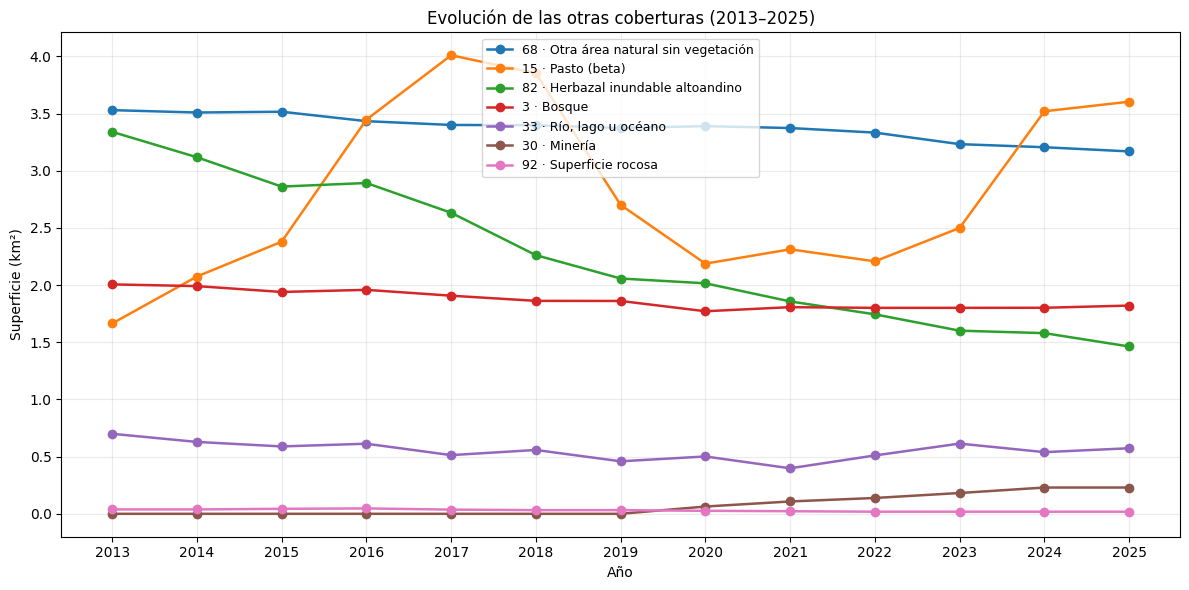

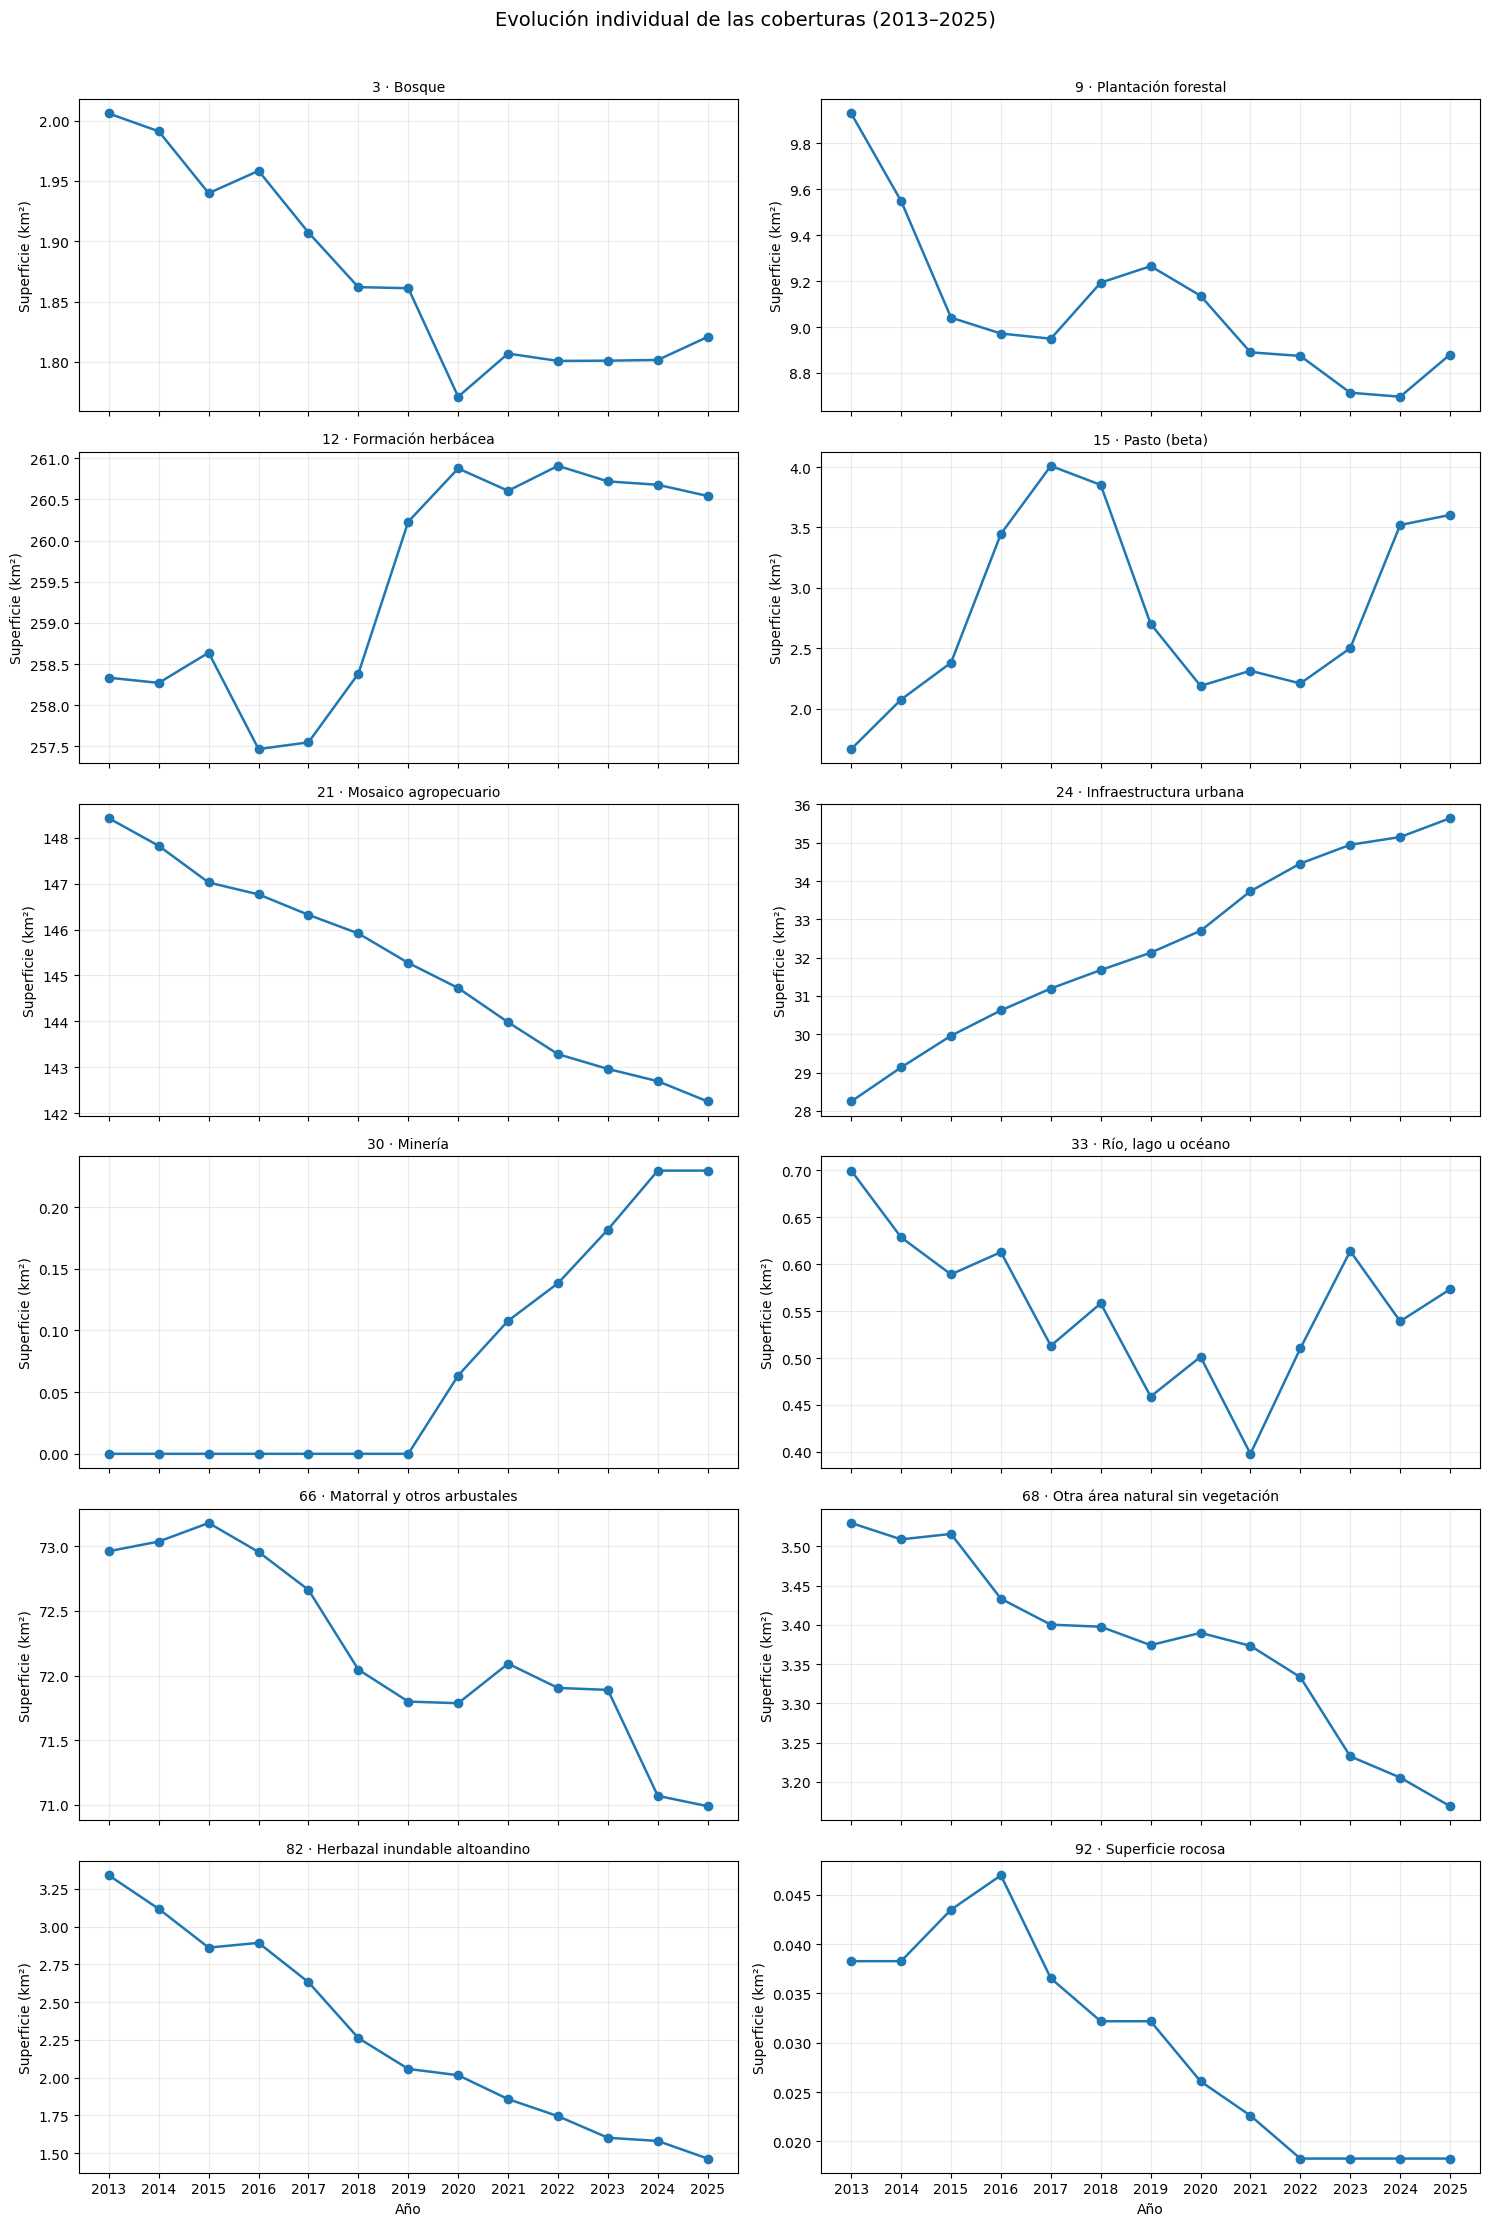

anio,codigo,nombre,superficie_2013_km2,superficie_2025_km2,variacion_km2,variacion_pct
5,24,Infraestructura urbana,28.247,35.640,7.393,26.172
2,12,Formación herbácea,258.334,260.541,2.206,0.854
3,15,Pasto (beta),1.664,3.603,1.939,116.532
6,30,Minería,0.000,0.230,0.230,NaN
11,92,Superficie rocosa,0.038,0.018,-0.020,-52.275
7,33,"Río, lago u océano",0.700,0.573,-0.126,-18.071
0,3,Bosque,2.006,1.821,-0.185,-9.230
9,68,Otra área natural sin vegetación,3.530,3.169,-0.361,-10.226
1,9,Plantación forestal,9.929,8.880,-1.049,-10.560
10,82,Herbazal inundable altoandino,3.340,1.463,-1.877,-56.193


Archivo guardado: d:\workspace\projects\project-collab\cusco-land-cover-analysis\outputs\02_mapbiomas_cover_ref\variacion_cobertura_2013_2025.csv


In [8]:
# ============================================================
# EVOLUCIÓN TEMPORAL DE LAS COBERTURAS
# ============================================================

# Matriz de superficies: años x clases.
tabla_areas = (
    areas.pivot(index="anio", columns="clase", values="km2")
    .reindex(index=ANIOS, columns=sorted(CODIGOS_ANALISIS))
    .fillna(0)
)

# Clasificar las coberturas según su superficie acumulada.
superficie_acumulada = tabla_areas.sum(axis=0).sort_values(
    ascending=False
)

# Cinco clases con mayor extensión acumulada.
cinco_principales = superficie_acumulada.head(5).index.tolist()

# Siete clases restantes.
otras_clases = superficie_acumulada.iloc[5:].index.tolist()


# ------------------------------------------------------------
# Gráfico 1: cinco coberturas de mayor extensión
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

for codigo in cinco_principales:
    ax.plot(
        tabla_areas.index,
        tabla_areas[codigo],
        marker="o",
        linewidth=1.8,
        label=f"{codigo} · {NOMBRES[codigo]}"
    )

ax.set_title(
    f"Evolución de las cinco principales coberturas ({ANIO_INI}–{ANIO_FIN})"
)
ax.set_xlabel("Año")
ax.set_ylabel("Superficie (km²)")
ax.set_xticks(ANIOS)
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Gráfico 2: siete coberturas restantes
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

for codigo in otras_clases:
    ax.plot(
        tabla_areas.index,
        tabla_areas[codigo],
        marker="o",
        linewidth=1.8,
        label=f"{codigo} · {NOMBRES[codigo]}"
    )

ax.set_title(
    f"Evolución de las otras coberturas ({ANIO_INI}–{ANIO_FIN})"
)
ax.set_xlabel("Año")
ax.set_ylabel("Superficie (km²)")
ax.set_xticks(ANIOS)
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Gráfico 3: evolución individual de las 12 coberturas
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=6,
    ncols=2,
    figsize=(15, 22),
    sharex=True
)

axes = axes.flatten()

for ax, codigo in zip(axes, sorted(CODIGOS_ANALISIS)):
    ax.plot(
        tabla_areas.index,
        tabla_areas[codigo],
        marker="o",
        linewidth=1.8
    )

    ax.set_title(
        f"{codigo} · {NOMBRES[codigo]}",
        fontsize=10
    )
    ax.set_ylabel("Superficie (km²)")
    ax.set_xticks(ANIOS)
    ax.grid(alpha=0.25)

# Etiquetas del eje X.
for ax in axes[-2:]:
    ax.set_xlabel("Año")

fig.suptitle(
    f"Evolución individual de las coberturas ({ANIO_INI}–{ANIO_FIN})",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# VARIACIÓN DE SUPERFICIE ENTRE 2013 Y 2025
# ============================================================

variacion = (
    tabla_areas.loc[[ANIO_INI, ANIO_FIN]]
    .T
    .rename(columns={
        ANIO_INI: f"superficie_{ANIO_INI}_km2",
        ANIO_FIN: f"superficie_{ANIO_FIN}_km2"
    })
    .reset_index()
    .rename(columns={"clase": "codigo"})
)

variacion["nombre"] = variacion["codigo"].map(NOMBRES)

col_ini = f"superficie_{ANIO_INI}_km2"
col_fin = f"superficie_{ANIO_FIN}_km2"

variacion["variacion_km2"] = (
    variacion[col_fin] - variacion[col_ini]
)

variacion["variacion_pct"] = np.where(
    variacion[col_ini] > 0,
    variacion["variacion_km2"] / variacion[col_ini] * 100,
    np.nan
)

variacion = variacion[
    [
        "codigo",
        "nombre",
        col_ini,
        col_fin,
        "variacion_km2",
        "variacion_pct"
    ]
].sort_values("variacion_km2", ascending=False)

archivo_variacion = SALIDA / "variacion_cobertura_2013_2025.csv"

variacion.to_csv(
    archivo_variacion,
    index=False,
    encoding="utf-8-sig"
)

display(variacion.round(3))

print(f"Archivo guardado: {archivo_variacion}")

## 5. Matrices completas de transición

Las filas representan las clases del año inicial y las columnas las clases del año final. Cada celda contiene la superficie que pasó de una clase a otra. Se incluyen todas las combinaciones entre las clases presentes durante el periodo; las combinaciones sin píxeles se registran con cero.

Se genera una matriz para 2013–2025 y una para cada par de años consecutivos.

In [9]:
# ============================================================
# MATRICES DE TRANSICIÓN DE COBERTURA
# ============================================================

CODIGOS_TRANSICION = sorted(CODIGOS_ANALISIS)


# ------------------------------------------------------------
# Cálculo de transiciones entre dos años
# ------------------------------------------------------------

def matriz_transicion(anio_a, anio_b):

    origen = mb.select(
        f"classification_{anio_a}"
    ).rename("origen")

    destino = mb.select(
        f"classification_{anio_b}"
    ).rename("destino")

    # Conservar únicamente píxeles pertenecientes
    # a las 12 clases seleccionadas en ambos años.
    mascara_origen = origen.remap(
        CODIGOS_TRANSICION,
        [1] * len(CODIGOS_TRANSICION),
        0
    ).eq(1)

    mascara_destino = destino.remap(
        CODIGOS_TRANSICION,
        [1] * len(CODIGOS_TRANSICION),
        0
    ).eq(1)

    mascara = mascara_origen.And(mascara_destino)

    # Codificación del par origen-destino.
    par = origen.multiply(100).add(destino).rename("par")

    imagen = (
        ee.Image.pixelArea()
        .divide(1e6)
        .rename("km2")
        .addBands(par)
        .updateMask(mascara)
    )

    resultado = imagen.reduceRegion(
        reducer=ee.Reducer.sum().group(
            groupField=1,
            groupName="par"
        ),
        geometry=aoi,
        scale=ESCALA,
        crs=proyeccion,
        maxPixels=MAX_PIXELS,
        tileScale=TILE_SCALE
    )

    return resultado.get("groups")


# ------------------------------------------------------------
# Periodos de análisis
# ------------------------------------------------------------

periodos = (
    [(ANIO_INI, ANIO_FIN)]
    + list(zip(ANIOS[:-1], ANIOS[1:]))
)

grupos_periodo = evaluar_serie(
    [matriz_transicion(a, b) for a, b in periodos],
    [f"Matriz {a} → {b}" for a, b in periodos]
)


# ------------------------------------------------------------
# Organización de transiciones observadas
# ------------------------------------------------------------

registros = []

for (a, b), grupos in zip(periodos, grupos_periodo):

    for g in (grupos or []):

        par = int(g["par"])
        origen = par // 100
        destino = par % 100

        registros.append({
            "periodo": f"{a}-{b}",
            "anio_origen": a,
            "anio_destino": b,
            "origen": origen,
            "destino": destino,
            "km2": float(g["sum"])
        })

observadas = pd.DataFrame(registros)


# ------------------------------------------------------------
# Completar matrices con todas las combinaciones
# ------------------------------------------------------------

indice = pd.MultiIndex.from_product(
    [CODIGOS_TRANSICION, CODIGOS_TRANSICION],
    names=["origen", "destino"]
)

matrices = []

for a, b in periodos:

    periodo = f"{a}-{b}"

    sub = observadas[
        observadas["periodo"] == periodo
    ]

    if not sub.empty:
        sub = sub.set_index(["origen", "destino"])
        sub = sub[["km2"]]
    else:
        sub = pd.DataFrame(columns=["km2"], index=indice)

    sub = sub.reindex(indice, fill_value=0).reset_index()

    sub["periodo"] = periodo
    sub["anio_origen"] = a
    sub["anio_destino"] = b

    sub["clase_origen"] = sub["origen"].map(NOMBRES)
    sub["clase_destino"] = sub["destino"].map(NOMBRES)

    matrices.append(sub)


matrices = pd.concat(matrices, ignore_index=True)

matrices = matrices[
    [
        "periodo",
        "anio_origen",
        "anio_destino",
        "origen",
        "clase_origen",
        "destino",
        "clase_destino",
        "km2"
    ]
]


# ------------------------------------------------------------
# Exportación de matrices completas
# ------------------------------------------------------------

archivo_matrices = SALIDA / "matrices_transicion_completas.csv"

matrices.to_csv(
    archivo_matrices,
    index=False,
    encoding="utf-8-sig"
)

print("Clases analizadas:", len(CODIGOS_TRANSICION))
print("Combinaciones por matriz:", len(CODIGOS_TRANSICION) ** 2)
print("Periodos procesados:", len(periodos))
print("Archivo guardado:", archivo_matrices)


# ------------------------------------------------------------
# Matriz de transición 2013–2025
# ------------------------------------------------------------

matriz_final = (
    matrices[
        matrices["periodo"] == f"{ANIO_INI}-{ANIO_FIN}"
    ]
    .pivot(
        index="clase_origen",
        columns="clase_destino",
        values="km2"
    )
)

display(matriz_final.round(3))

[1/13] Matriz 2013 → 2025... OK
[2/13] Matriz 2013 → 2014... OK
[3/13] Matriz 2014 → 2015... OK
[4/13] Matriz 2015 → 2016... OK
[5/13] Matriz 2016 → 2017... OK
[6/13] Matriz 2017 → 2018... OK
[7/13] Matriz 2018 → 2019... OK
[8/13] Matriz 2019 → 2020... OK
[9/13] Matriz 2020 → 2021... OK
[10/13] Matriz 2021 → 2022... OK
[11/13] Matriz 2022 → 2023... OK
[12/13] Matriz 2023 → 2024... OK
[13/13] Matriz 2024 → 2025... OK
Clases analizadas: 12
Combinaciones por matriz: 144
Periodos procesados: 13
Archivo guardado: d:\workspace\projects\project-collab\cusco-land-cover-analysis\outputs\02_mapbiomas_cover_ref\matrices_transicion_completas.csv


clase_destino,Bosque,Formación herbácea,Herbazal inundable altoandino,Infraestructura urbana,Matorral y otros arbustales,Minería,Mosaico agropecuario,Otra área natural sin vegetación,Pasto (beta),Plantación forestal,"Río, lago u océano",Superficie rocosa
clase_origen,,,,,,,,,,,,
Bosque,1.669,0.098,0.002,0.000,0.198,0.000,0.024,0.000,0.007,0.007,0.000,0.000
Formación herbácea,0.025,254.931,0.198,0.107,0.204,0.211,0.923,0.018,1.646,0.054,0.017,0.000
Herbazal inundable altoandino,0.000,1.215,1.251,0.000,0.006,0.000,0.000,0.000,0.781,0.078,0.010,0.000
Infraestructura urbana,0.000,0.000,0.000,28.213,0.001,0.000,0.004,0.000,0.000,0.000,0.029,0.000
Matorral y otros arbustales,0.077,2.101,0.002,0.451,68.959,0.009,0.388,0.039,0.001,0.936,0.000,0.000
Minería,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Mosaico agropecuario,0.035,1.485,0.000,6.399,0.131,0.000,140.089,0.011,0.177,0.077,0.023,0.000
Otra área natural sin vegetación,0.000,0.014,0.000,0.410,0.009,0.000,0.056,3.039,0.000,0.000,0.003,0.000
Pasto (beta),0.014,0.635,0.010,0.000,0.000,0.000,0.014,0.000,0.991,0.000,0.000,0.000


## 6. Indicadores de cambio en bosques y expansión agrícola

Se calculan indicadores diferenciados para los dos objetivos del estudio:

- **Cambio en bosques naturales:** pérdida, ganancia, persistencia y transiciones hacia/desde otras coberturas.
- **Expansión agrícola:** transición desde coberturas distintas de la clase agropecuaria principal (21, mosaico agropecuario) hacia dicha clase.
- **Conversión directa de bosque a cobertura agropecuaria:** subconjunto que permite relacionar ambos fenómenos.

La clase 15 (Pasto beta) se analiza por separado como escenario complementario, porque puede representar pastos naturales altoandinos y no necesariamente expansión agrícola. Las clases 35 y 40 se conservan en la definición conceptual del TDR, pero no forman parte de las 12 clases observadas en el AOI.

In [10]:
# ============================================================
# 6. INDICADORES DE CAMBIO EN BOSQUES Y EXPANSIÓN AGRÍCOLA
# ============================================================

CODIGOS_TRANSICION = sorted(CODIGOS_ANALISIS)

# Definiciones temáticas del análisis.
CLASES_BOSQUE = set(CLASES_BOSQUE_NATURAL)
CLASE_AGRICOLA_PRINCIPAL = 21       # Mosaico agropecuario
CLASE_PASTO_COMPLEMENTARIA = 15    # Pasto beta: no asumir uso agropecuario
CLASES_AGROPECUARIAS_OBSERVADAS = {
    c for c in [21, 35, 40] if c in CODIGOS_TRANSICION
}

# Clases no boscosas, para conservar los indicadores existentes.
OTRAS_CLASES = [
    codigo for codigo in CODIGOS_TRANSICION
    if codigo not in CLASES_BOSQUE
]


# ------------------------------------------------------------
# Cálculo de indicadores para un periodo
# ------------------------------------------------------------

def indicadores_periodo(m):

    origen = m["origen"]
    destino = m["destino"]
    km2 = m["km2"]

    bosque_origen = origen.isin(CLASES_BOSQUE)
    bosque_destino = destino.isin(CLASES_BOSQUE)

    indicadores = {
        # Cambio en bosque natural.
        "perdida_bosque_natural_km2": km2[
            bosque_origen & ~bosque_destino
        ].sum(),

        "ganancia_bosque_natural_km2": km2[
            ~bosque_origen & bosque_destino
        ].sum(),

        "bosque_persistente_km2": km2[
            bosque_origen & bosque_destino
        ].sum(),

        # Expansión agrícola principal: cualquier clase distinta de 21
        # que pasa a mosaico agropecuario (21).
        "expansion_mosaico_agropecuario_km2": km2[
            (origen != CLASE_AGRICOLA_PRINCIPAL)
            & (destino == CLASE_AGRICOLA_PRINCIPAL)
        ].sum(),

        # Transición desde bosque natural directamente a clase 21.
        "bosque_a_mosaico_agropecuario_km2": km2[
            bosque_origen
            & (destino == CLASE_AGRICOLA_PRINCIPAL)
        ].sum(),

        # Transición hacia clase 21 desde coberturas no boscosas.
        "otras_coberturas_a_mosaico_agropecuario_km2": km2[
            ~bosque_origen
            & (origen != CLASE_AGRICOLA_PRINCIPAL)
            & (destino == CLASE_AGRICOLA_PRINCIPAL)
        ].sum(),

        # Clase 15 se informa por separado; no se suma a la expansión
        # agrícola principal debido a su ambigüedad temática.
        "transiciones_hacia_pasto_beta_15_km2": km2[
            (origen != CLASE_PASTO_COMPLEMENTARIA)
            & (destino == CLASE_PASTO_COMPLEMENTARIA)
        ].sum(),

        "bosque_a_pasto_beta_15_km2": km2[
            bosque_origen
            & (destino == CLASE_PASTO_COMPLEMENTARIA)
        ].sum()
    }

    # Se mantienen los indicadores detallados de bosque existentes.
    for codigo in OTRAS_CLASES:
        indicadores[f"bosque_a_{codigo}_km2"] = km2[
            bosque_origen & (destino == codigo)
        ].sum()

    for codigo in OTRAS_CLASES:
        indicadores[f"{codigo}_a_bosque_km2"] = km2[
            (origen == codigo) & bosque_destino
        ].sum()

    # Flujos desde/hacia cada clase agropecuaria observada (21, y 35/40
    # si estuvieran presentes en el AOI).
    for codigo in sorted(CLASES_AGROPECUARIAS_OBSERVADAS):
        indicadores[f"expansion_hacia_agropecuaria_{codigo}_km2"] = km2[
            (origen != codigo) & (destino == codigo)
        ].sum()

        indicadores[f"agropecuaria_{codigo}_desde_bosque_km2"] = km2[
            bosque_origen & (destino == codigo)
        ].sum()

    return indicadores


# ------------------------------------------------------------
# Calcular indicadores para todos los periodos
# ------------------------------------------------------------

filas_indicadores = []

for a, b in periodos:
    periodo = f"{a}-{b}"
    sub = matrices[matrices["periodo"] == periodo]

    filas_indicadores.append({
        "periodo": periodo,
        **indicadores_periodo(sub)
    })

indicadores = pd.DataFrame(filas_indicadores)


# ------------------------------------------------------------
# Exportar resultados
# ------------------------------------------------------------

archivo_indicadores = (
    SALIDA / "indicadores_cambio_bosque_expansion_agricola.csv"
)

indicadores.to_csv(
    archivo_indicadores,
    index=False,
    encoding="utf-8-sig"
)

display(indicadores.round(3))

print("Clases de transición:", len(CODIGOS_TRANSICION))
print("Clase agrícola principal:", CLASE_AGRICOLA_PRINCIPAL)
print("Clase complementaria separada:", CLASE_PASTO_COMPLEMENTARIA)
print("Periodos procesados:", len(periodos))
print("Archivo guardado:", archivo_indicadores)


,periodo,perdida_bosque_natural_km2,ganancia_bosque_natural_km2,bosque_persistente_km2,expansion_mosaico_agropecuario_km2,bosque_a_mosaico_agropecuario_km2,otras_coberturas_a_mosaico_agropecuario_km2,transiciones_hacia_pasto_beta_15_km2,bosque_a_pasto_beta_15_km2,bosque_a_9_km2,...,21_a_bosque_km2,24_a_bosque_km2,30_a_bosque_km2,33_a_bosque_km2,66_a_bosque_km2,68_a_bosque_km2,82_a_bosque_km2,92_a_bosque_km2,expansion_hacia_agropecuaria_21_km2,agropecuaria_21_desde_bosque_km2
0,2013-2025,0.337,0.152,1.669,2.164,0.024,2.139,2.612,0.007,0.007,...,0.035,0.0,0.0,0.0,0.077,0.0,0.000,0.0,2.164,0.024
1,2013-2014,0.075,0.060,1.931,0.694,0.035,0.659,0.715,0.006,0.000,...,0.001,0.0,0.0,0.0,0.030,0.0,0.000,0.0,0.694,0.035
2,2014-2015,0.072,0.021,1.919,0.502,0.010,0.492,0.802,0.004,0.001,...,0.004,0.0,0.0,0.0,0.010,0.0,0.000,0.0,0.502,0.010
3,2015-2016,0.054,0.072,1.886,0.723,0.005,0.717,1.155,0.011,0.000,...,0.017,0.0,0.0,0.0,0.033,0.0,0.001,0.0,0.723,0.005
4,2016-2017,0.070,0.019,1.888,0.407,0.008,0.399,0.714,0.001,0.000,...,0.001,0.0,0.0,0.0,0.009,0.0,0.001,0.0,0.407,0.008
5,2017-2018,0.077,0.031,1.831,0.533,0.003,0.531,0.409,0.003,0.001,...,0.005,0.0,0.0,0.0,0.023,0.0,0.002,0.0,0.533,0.003
6,2018-2019,0.056,0.055,1.806,0.460,0.005,0.455,0.176,0.000,0.004,...,0.025,0.0,0.0,0.0,0.015,0.0,0.002,0.0,0.460,0.005
7,2019-2020,0.105,0.015,1.757,0.441,0.004,0.437,0.167,0.002,0.000,...,0.002,0.0,0.0,0.0,0.009,0.0,0.001,0.0,0.441,0.004
8,2020-2021,0.028,0.064,1.743,0.508,0.005,0.503,0.354,0.002,0.001,...,0.013,0.0,0.0,0.0,0.031,0.0,0.003,0.0,0.508,0.005
9,2021-2022,0.035,0.029,1.772,0.443,0.003,0.440,0.170,0.001,0.000,...,0.011,0.0,0.0,0.0,0.008,0.0,0.000,0.0,0.443,0.003


Clases de transición: 12
Clase agrícola principal: 21
Clase complementaria separada: 15
Periodos procesados: 13
Archivo guardado: d:\workspace\projects\project-collab\cusco-land-cover-analysis\outputs\02_mapbiomas_cover_ref\indicadores_cambio_bosque_expansion_agricola.csv


## 7. Ubicación de las transiciones de bosque natural y expansión agrícola

Este análisis describe la variación cartográfica de bosque hacia distintos destinos y expansión agrícola. La conversión directa hacia coberturas agropecuarias se cuantifica por separado en los indicadores y en el análisis espacial agrícola.

In [15]:

# ============================================================
# 7. MAPA HTML INTEGRADO DE TRANSICIONES DE COBERTURA
#    BOSQUE NATURAL Y EXPANSIÓN AGRÍCOLA (2013–2025)
# ============================================================

import geemap
import geopandas as gpd
import folium
from folium import plugins
from branca.element import Template, MacroElement

# ============================================================
# 1. PREPARACIÓN DE COBERTURAS
# ============================================================

bosque_inicial = mb.select(f"classification_{ANIO_INI}")
cobertura_final = mb.select(f"classification_{ANIO_FIN}")

# ------------------------------------------------------------
# 1.1. Máscara de bosque natural inicial
# ------------------------------------------------------------

mascara_bosque = (
    bosque_inicial
    .remap(
        sorted(CLASES_BOSQUE_NATURAL),
        [1] * len(CLASES_BOSQUE_NATURAL),
        0
    )
    .eq(1)
)

# ------------------------------------------------------------
# 1.2. Clases de destino de las transiciones de bosque
# ------------------------------------------------------------

OTRAS_CLASES = sorted(
    set(CODIGOS_ANALISIS) -
    set(CLASES_BOSQUE_NATURAL)
)

print("Clases de destino de bosque:", OTRAS_CLASES)

# ------------------------------------------------------------
# 1.3. Máscara de origen válido para expansión agrícola
# ------------------------------------------------------------

mascara_origen_valido_agri = (
    bosque_inicial
    .remap(
        CODIGOS_ANALISIS,
        [1] * len(CODIGOS_ANALISIS),
        0
    )
    .eq(1)
)

# ------------------------------------------------------------
# 1.4. Expansión agrícola principal: clase 21
# ------------------------------------------------------------

mascara_expansion_agricola = (
    mascara_origen_valido_agri
    .And(
        bosque_inicial.neq(CLASE_AGRICOLA_PRINCIPAL)
    )
    .And(
        cobertura_final.eq(CLASE_AGRICOLA_PRINCIPAL)
    )
    .selfMask()
    .clip(aoi)
)

# ------------------------------------------------------------
# 1.5. Expansión complementaria: clase 15
# ------------------------------------------------------------

mascara_expansion_pasto_beta = (
    mascara_origen_valido_agri
    .And(
        bosque_inicial.neq(CLASE_PASTO_COMPLEMENTARIA)
    )
    .And(
        cobertura_final.eq(CLASE_PASTO_COMPLEMENTARIA)
    )
    .selfMask()
    .clip(aoi)
)

# ============================================================
# 2. PALETA DE COLORES
# ============================================================

COLORES_TRANSICION = {
    9:  "a6761d",
    12: "7570b3",
    15: "e6ab02",
    21: "66a61e",
    24: "e7298a",
    30: "d73027",
    33: "1f78b4",
    66: "bdbdbd",
    68: "969696",
    82: "80cdc1",
    92: "636363"
}

# Verificar colores de las clases de destino

clases_sin_color = [
    codigo
    for codigo in OTRAS_CLASES
    if codigo not in COLORES_TRANSICION
]

if clases_sin_color:
    raise ValueError(
        f"Faltan colores para las clases: {clases_sin_color}"
    )

# Verificar nombres de las clases

clases_sin_nombre = [
    codigo
    for codigo in OTRAS_CLASES
    if codigo not in NOMBRES
]

if clases_sin_nombre:
    raise ValueError(
        f"Faltan nombres para las clases: {clases_sin_nombre}"
    )

# ============================================================
# 3. PREPARACIÓN DEL ÁREA DE ESTUDIO
# ============================================================

RUTA_AOI = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "prov"
    / "cusco-aoi.geojson"
)

gdf_aoi = gpd.read_file(RUTA_AOI)

if gdf_aoi.empty:
    raise ValueError("El GeoJSON del AOI está vacío.")

if gdf_aoi.crs is None:
    raise ValueError("El GeoJSON no tiene un CRS definido.")

gdf_aoi = gdf_aoi.to_crs("EPSG:4326")

lon_min, lat_min, lon_max, lat_max = (
    gdf_aoi.total_bounds
)

lat_centro = (lat_min + lat_max) / 2
lon_centro = (lon_min + lon_max) / 2

# ============================================================
# 4. CREACIÓN DEL MAPA
# ============================================================

Map_Transiciones = folium.Map(
    location=[lat_centro, lon_centro],
    zoom_start=9,
    control_scale=True,
    tiles=None
)

# ------------------------------------------------------------
# 4.1. Satélite
# ------------------------------------------------------------

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/"
        "services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri World Imagery",
    name="Satélite (Esri)",
    overlay=False,
    control=True
).add_to(Map_Transiciones)

# ------------------------------------------------------------
# 4.2. OpenStreetMap
# ------------------------------------------------------------

folium.TileLayer(
    "OpenStreetMap",
    name="OpenStreetMap",
    overlay=False,
    control=True
).add_to(Map_Transiciones)

# ------------------------------------------------------------
# 4.3. Límite del área de estudio
# ------------------------------------------------------------

folium.GeoJson(
    gdf_aoi.to_json(),
    name="Límite provincial del AOI",
    style_function=lambda feature: {
        "color": "#ffffff",
        "weight": 2,
        "fillOpacity": 0
    }
).add_to(Map_Transiciones)

# ============================================================
# 5. TRANSICIONES DE BOSQUE NATURAL
# ============================================================

for codigo in OTRAS_CLASES:

    transicion = (
        mascara_bosque
        .And(cobertura_final.eq(codigo))
        .selfMask()
        .clip(aoi)
    )

    parametros_vis = {
        "min": 0,
        "max": 1,
        "palette": [COLORES_TRANSICION[codigo]]
    }

    map_id = transicion.getMapId(parametros_vis)

    folium.TileLayer(
        tiles=map_id["tile_fetcher"].url_format,
        attr="Google Earth Engine",
        name=(
            f"Bosque natural → {codigo} · "
            f"{NOMBRES[codigo]}"
        ),
        overlay=True,
        control=True,
        show=False,
        opacity=0.85
    ).add_to(Map_Transiciones)

    print(
        f"[INFO] Transición añadida: "
        f"Bosque natural → {codigo} ({NOMBRES[codigo]})"
    )

# ============================================================
# 6. EXPANSIÓN AGRÍCOLA PRINCIPAL: CLASE 21
# ============================================================

map_id_21 = mascara_expansion_agricola.getMapId({
    "min": 0,
    "max": 1,
    "palette": ["66a61e"]
})

folium.TileLayer(
    tiles=map_id_21["tile_fetcher"].url_format,
    attr="Google Earth Engine",
    name="Expansión agrícola → Mosaico agropecuario (21)",
    overlay=True,
    control=True,
    show=True,
    opacity=0.85
).add_to(Map_Transiciones)

print("[INFO] Expansión agrícola clase 21 añadida.")

# ============================================================
# 7. EXPANSIÓN COMPLEMENTARIA: CLASE 15
# ============================================================

map_id_15 = mascara_expansion_pasto_beta.getMapId({
    "min": 0,
    "max": 1,
    "palette": ["e6ab02"]
})

folium.TileLayer(
    tiles=map_id_15["tile_fetcher"].url_format,
    attr="Google Earth Engine",
    name="Expansión complementaria → Pasto beta (15)",
    overlay=True,
    control=True,
    show=False,
    opacity=0.85
).add_to(Map_Transiciones)

print("[INFO] Expansión complementaria clase 15 añadida.")

# ============================================================
# 8. CONTROLES CARTOGRÁFICOS
# ============================================================

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(Map_Transiciones)

plugins.MeasureControl(
    position="topleft",
    active_color="#ff0000",
    completed_color="#00ff00",
    primary_length_unit="kilometers",
    secondary_length_unit="meters",
    primary_area_unit="hectares",
    secondary_area_unit="sqmeters"
).add_to(Map_Transiciones)

plugins.Fullscreen(
    position="topleft",
    title="Ver pantalla completa",
    title_cancel="Salir de pantalla completa",
    force_separate_button=True
).add_to(Map_Transiciones)

# ============================================================
# 9. LEYENDA CARTOGRÁFICA
# ============================================================

elementos_leyenda_bosque = ""

for codigo in OTRAS_CLASES:

    color = COLORES_TRANSICION[codigo]
    nombre = NOMBRES[codigo]

    elementos_leyenda_bosque += f"""
    <div class="legend-item">
        <span class="legend-color"
              style="background:#{color};"></span>
        <span>Bosque natural → {codigo} · {nombre}</span>
    </div>
    """

template_leyenda = f"""
{{% macro html(this, kwargs) %}}

<div id="map-legend">

    <div class="legend-title">
        LEYENDA CARTOGRÁFICA
    </div>

    <div class="legend-period">
        Transiciones de cobertura ({ANIO_INI}–{ANIO_FIN})
    </div>

    <hr>

    <b>1. Transiciones de bosque natural</b>

    <div class="legend-subtitle">
        Bosque inicial → Cobertura final
    </div>

    {elementos_leyenda_bosque}

    <hr>

    <b>2. Expansión agrícola principal</b>

    <div class="legend-item">
        <span class="legend-color"
              style="background:#66a61e;"></span>
        <span>Otras coberturas → Mosaico agropecuario (21)</span>
    </div>

    <hr>

    <b>3. Expansión complementaria</b>

    <div class="legend-item">
        <span class="legend-color"
              style="background:#e6ab02;"></span>
        <span>Otras coberturas → Pasto beta (15)</span>
    </div>

    <hr>

    <b>4. Elementos de referencia</b>

    <div class="legend-item">
        <span class="legend-border"></span>
        <span>Límite provincial del AOI</span>
    </div>

    <div class="legend-footer">
        Fuente: Clasificación de coberturas
        mediante Google Earth Engine
    </div>

</div>

<style>

#map-legend {{
    position: fixed;
    bottom: 35px;
    left: 35px;
    width: 310px;
    max-height: 65vh;
    overflow-y: auto;
    z-index: 9999;
    background: rgba(255,255,255,0.96);
    border: 2px solid #555;
    border-radius: 8px;
    padding: 12px 15px;
    font-family: Arial, sans-serif;
    font-size: 12px;
    color: #222;
    box-shadow: 0 2px 8px rgba(0,0,0,0.35);
}}

.legend-title {{
    font-size: 15px;
    font-weight: bold;
    text-align: center;
    color: #1b4332;
}}

.legend-period {{
    font-size: 11px;
    text-align: center;
    margin: 5px 0 12px;
    color: #555;
}}

.legend-item {{
    display: flex;
    align-items: center;
    margin: 5px 0;
    line-height: 1.35;
}}

.legend-color {{
    display: inline-block;
    flex-shrink: 0;
    width: 15px;
    height: 15px;
    margin-right: 8px;
    border: 1px solid #777;
    border-radius: 2px;
}}

.legend-border {{
    width: 15px;
    height: 15px;
    flex-shrink: 0;
    margin-right: 8px;
    border: 2px solid white;
    outline: 1px solid #555;
    background: #ddd;
}}

.legend-subtitle {{
    font-size: 10px;
    color: #666;
    margin: 5px 0;
}}

.legend-footer {{
    margin-top: 10px;
    padding-top: 7px;
    border-top: 1px solid #ccc;
    font-size: 10px;
    color: #666;
    text-align: center;
}}

@media (max-width: 600px) {{
    #map-legend {{
        left: 10px;
        bottom: 15px;
        width: 260px;
        font-size: 11px;
    }}
}}

</style>

{{% endmacro %}}
"""

leyenda = MacroElement()
leyenda._template = Template(template_leyenda)

Map_Transiciones.get_root().add_child(leyenda)

print("[INFO] Leyenda cartográfica añadida.")

# ============================================================
# 10. AJUSTAR EXTENSIÓN ESPACIAL
# ============================================================

Map_Transiciones.fit_bounds([
    [lat_min, lon_min],
    [lat_max, lon_max]
])

# ============================================================
# 11. GUARDAR MAPA HTML
# ============================================================

RUTA_MAPA_INTEGRADO = (
    SALIDA /
    "mapa_integrado_transiciones_bosque_expansion_agricola.html"
)

Map_Transiciones.save(str(RUTA_MAPA_INTEGRADO))

# ============================================================
# 12. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("MAPA INTEGRADO GENERADO CORRECTAMENTE")
print("=" * 65)

print(f"[INFO] Periodo: {ANIO_INI}–{ANIO_FIN}")
print(f"[INFO] Transiciones de bosque: {len(OTRAS_CLASES)}")
print("[INFO] Expansión agrícola principal: clase 21")
print("[INFO] Expansión complementaria: clase 15")
print(f"[INFO] Archivo HTML: {RUTA_MAPA_INTEGRADO}")

display(Map_Transiciones)


Clases de destino de bosque: [9, 12, 15, 21, 24, 30, 33, 66, 68, 82, 92]
[INFO] Transición añadida: Bosque natural → 9 (Plantación forestal)
[INFO] Transición añadida: Bosque natural → 12 (Formación herbácea)
[INFO] Transición añadida: Bosque natural → 15 (Pasto (beta))
[INFO] Transición añadida: Bosque natural → 21 (Mosaico agropecuario)
[INFO] Transición añadida: Bosque natural → 24 (Infraestructura urbana)
[INFO] Transición añadida: Bosque natural → 30 (Minería)
[INFO] Transición añadida: Bosque natural → 33 (Río, lago u océano)
[INFO] Transición añadida: Bosque natural → 66 (Matorral y otros arbustales)
[INFO] Transición añadida: Bosque natural → 68 (Otra área natural sin vegetación)
[INFO] Transición añadida: Bosque natural → 82 (Herbazal inundable altoandino)
[INFO] Transición añadida: Bosque natural → 92 (Superficie rocosa)
[INFO] Expansión agrícola clase 21 añadida.
[INFO] Expansión complementaria clase 15 añadida.
[INFO] Leyenda cartográfica añadida.

MAPA INTEGRADO GENERADO C